# Pergunta 1.3: existem padrões diferentes por plataforma?

> **Pergunta do case:** existem padrões diferentes por plataforma? O que funciona no TikTok funciona no LinkedIn (por exemplo)?

O "TikTok × LinkedIn" é só um exemplo. A pergunta é geral: **o que funciona muda de uma plataforma para outra?** Por isso comparo as três plataformas da base (Meta, TikTok e LinkedIn) e **os três pares** (Meta × TikTok, Meta × LinkedIn, TikTok × LinkedIn), sem privilegiar nenhum.

| Passo | Pergunta | Ferramenta |
|---|---|---|
| 1 | Como cada plataforma é? | medianas por plataforma, eta² e crosstab |
| 2 | Quanto cada atributo muda o resultado dentro de cada rede? | diferença das medianas, com intervalo de 95% |
| 3 | O efeito de um atributo muda de uma rede para outra? | diferença entre os efeitos de cada par de redes, com intervalo de 95% |
| 4 | Então, o que funciona igual e o que funciona diferente? | regra de bolso + regressão dentro de cada rede |
| 5 | Existe uma duração ideal por rede? | mediana por faixa de duração |
| 6 | Formato × plataforma | cada par de formatos dentro de cada rede |
| 7 | Texto × plataforma | mediana por nível de texto |
| 8 | O manual de cada plataforma | os 3 maiores efeitos positivos e os 2 negativos |

Toda a análise usa só o **treino**. A explicação de cada decisão está em `docs/parte1/1_3_padroes_por_plataforma.md`.

## Passo 0: preparação

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.linear_model import LinearRegression

RAIZ = Path("../..")
sys.path.append(str(RAIZ))
from src.limpeza import carregar, limpar, separar_treino_teste

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)
CINZA, CINZA_CLARO = "#52514e", "#b8b7b1"
PLATAFORMAS = ["Meta", "TikTok", "LinkedIn"]
CORES_PLATAFORMA = {"Meta": "#2a78d6", "TikTok": "#eb6834", "LinkedIn": "#1baf7a"}


def estilo_limpo(ax):
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", color="#e5e5e5", linewidth=0.8)
    ax.set_axisbelow(True)


def eta2(valores, grupos):
    """Fração da variação de `valores` explicada só por saber o grupo (0 = nada, 1 = tudo)."""
    tem_valor = valores.notna()
    valores, grupos = valores[tem_valor], grupos[tem_valor]
    media_do_grupo = valores.groupby(grupos).transform("mean")
    return ((media_do_grupo - valores.mean()) ** 2).sum() / ((valores - valores.mean()) ** 2).sum()


def sortear_medianas(com, sem, sorteios=2000):
    """As 2000 medianas sorteadas (bootstrap) de cada grupo, sempre com a mesma semente."""
    com, sem = com.dropna().to_numpy(), sem.dropna().to_numpy()
    gerador = np.random.default_rng(42)
    medianas_com = np.median(com[gerador.integers(0, len(com), (sorteios, len(com)))], axis=1)
    medianas_sem = np.median(sem[gerador.integers(0, len(sem), (sorteios, len(sem)))], axis=1)
    return medianas_com, medianas_sem


def comparar(com, sem):
    """Diferença % das medianas (com ÷ sem − 1) e o intervalo de 95% por bootstrap (explicado no notebook 1.2)."""
    medianas_com, medianas_sem = sortear_medianas(com, sem)
    baixo, alto = np.percentile((medianas_com / medianas_sem - 1) * 100, [2.5, 97.5])
    com, sem = com.dropna(), sem.dropna()
    return {"n com": len(com), "n sem": len(sem), "mediana com": com.median(), "mediana sem": sem.median(),
            "diferença (%)": (com.median() / sem.median() - 1) * 100,
            "intervalo baixo (%)": baixo, "intervalo alto (%)": alto, "confiável?": baixo > 0 or alto < 0}

In [2]:
# Mesma divisão e limpeza do notebook 1.1; valores preenchidos voltam a vazio (como no notebook 1.2)
treino_bruto, teste_bruto = separar_treino_teste(carregar(RAIZ / "data/raw/klike_challenge_dataset.csv"))
reais = limpar(treino_bruto)
for coluna in ["video_duration_s", "music_voice_ratio", "avg_watch_time_s", "engagement_rate"]:
    reais.loc[reais[f"{coluna}_faltava"] == 1, coluna] = np.nan
reais["retencao"] = reais["avg_watch_time_s"] / reais["video_duration_s"]
reais.loc[reais["category"] == "Branding", "roas"] = np.nan  # ROAS não se aplica a Branding
print(reais["platform"].value_counts().to_dict())

{'Meta': 193, 'TikTok': 141, 'LinkedIn': 66}


## Passo 1: como cada plataforma é?

In [3]:
perfil = reais.groupby("platform").agg(
    criativos=("ctr", "size"),
    duracao_mediana=("video_duration_s", "median"),
    pct_vertical=("format", lambda f: (f == "vertical").mean() * 100),
    pct_retargeting=("is_retargeting", lambda r: r.mean() * 100),
    cpc=("cpc", "median"), cpm=("cpm", "median"), ctr=("ctr", "median"),
    engajamento=("engagement_rate", "median"), retencao=("retencao", "median"),
    taxa_conversao=("taxa_conversao", "median"), cpa=("cpa", "median"),
    roas_sem_branding=("roas", "median"), klike_score=("klike_score", "median"),
).loc[PLATAFORMAS]
perfil.round(3).T

platform,Meta,TikTok,LinkedIn
criativos,193.000,141.000,66.000
duracao_mediana,17.000,12.500,23.500
pct_vertical,45.078,86.525,13.636
pct_retargeting,26.425,24.113,18.182
cpc,0.800,0.510,2.485
cpm,49.063,26.782,130.580
ctr,0.066,0.062,0.060
engajamento,0.018,0.032,0.016
retencao,0.538,0.486,0.520
taxa_conversao,0.032,0.033,0.033


In [4]:
# Quanto da variação de cada métrica se explica só por saber a plataforma (eta²)
pd.Series({nome: eta2(reais[metrica], reais["platform"]) for nome, metrica in
           [("CPC", "cpc"), ("CPM", "cpm"), ("CTR", "ctr"), ("engajamento", "engagement_rate"),
            ("retenção", "retencao"), ("taxa de conversão", "taxa_conversao"), ("CPA", "cpa"), ("ROAS", "roas"),
            ("klike_score", "klike_score")]},
          name="eta² da plataforma").round(3).to_frame().T

,CPC,CPM,CTR,engajamento,retenção,taxa de conversão,CPA,ROAS,klike_score
eta² da plataforma,0.771,0.337,0.002,0.126,0.012,0.0,0.144,0.132,0.022


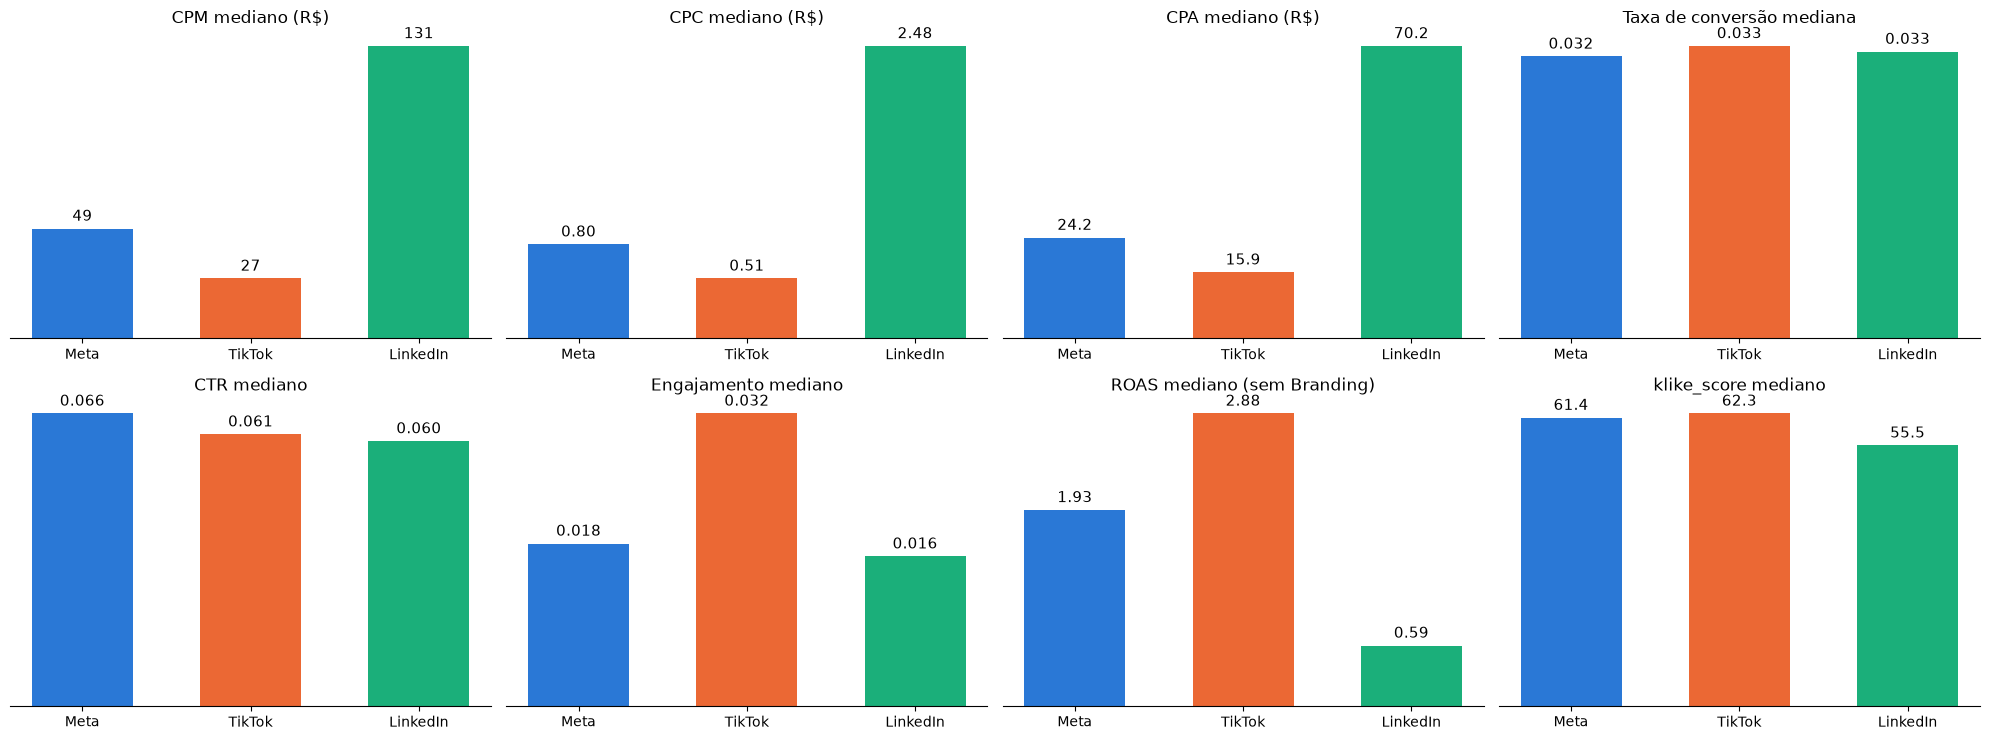

In [5]:
fig, eixos = plt.subplots(2, 4, figsize=(20, 7.5))
for ax, (coluna, titulo, formato) in zip(eixos.flat, [("cpm", "CPM mediano (R$)", "{:.0f}"), ("cpc", "CPC mediano (R$)", "{:.2f}"),
                                                 ("cpa", "CPA mediano (R$)", "{:.1f}"), ("taxa_conversao", "Taxa de conversão mediana", "{:.3f}"),
                                                 ("ctr", "CTR mediano", "{:.3f}"), ("engajamento", "Engajamento mediano", "{:.3f}"),
                                                 ("roas_sem_branding", "ROAS mediano (sem Branding)", "{:.2f}"),
                                                 ("klike_score", "klike_score mediano", "{:.1f}")]):
    barras = ax.bar(PLATAFORMAS, perfil[coluna], color=[CORES_PLATAFORMA[p] for p in PLATAFORMAS], width=0.6)
    ax.bar_label(barras, labels=[formato.format(v) for v in perfil[coluna]], padding=3, fontsize=11)
    ax.set_title(titulo, fontsize=12)
    ax.set_yticks([])
    ax.spines[["top", "right", "left"]].set_visible(False)
plt.tight_layout()
plt.show()

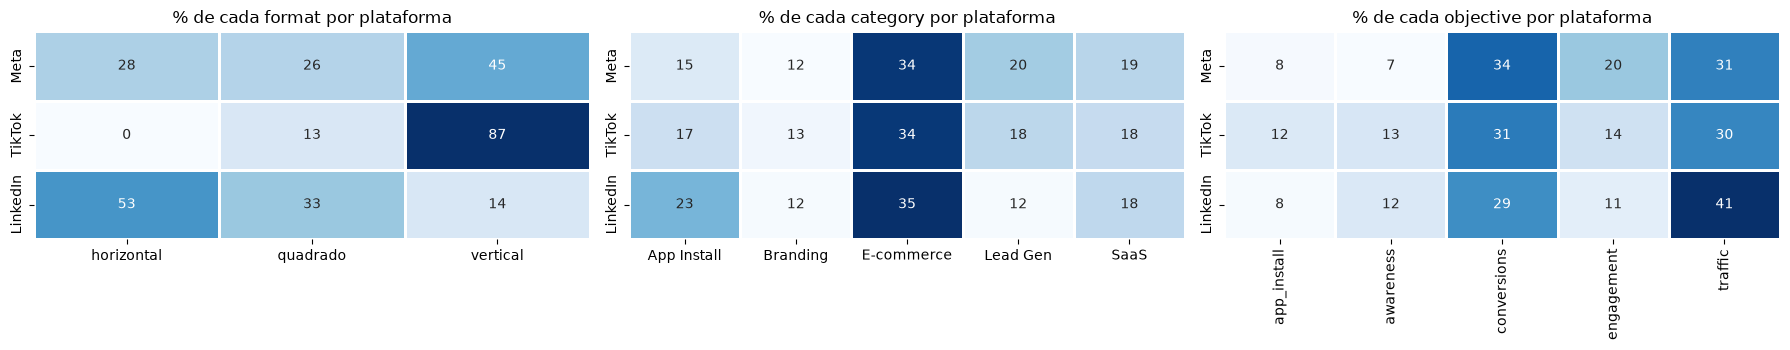

In [6]:
# O que cada plataforma veicula (% das linhas de cada plataforma)
fig, eixos = plt.subplots(1, 3, figsize=(18, 3.6))
for ax, coluna in zip(eixos, ["format", "category", "objective"]):
    sns.heatmap(pd.crosstab(reais["platform"], reais[coluna], normalize="index").loc[PLATAFORMAS] * 100,
                annot=True, fmt=".0f", cmap="Blues", cbar=False, ax=ax, linewidths=2, linecolor="white")
    ax.set_title(f"% de cada {coluna} por plataforma")
    ax.set_xlabel("")
    ax.set_ylabel("")
plt.tight_layout()
plt.show()

**Lendo o perfil:**

- **O custo muda muito de rede para rede:** CPM mediano de R$131 no LinkedIn, R$49 no Meta e R$27 no TikTok. O CPC do LinkedIn (R$2,49) é cerca de 5 vezes o do TikTok (R$0,51). A plataforma explica 77% da variação do CPC (eta² 0,77). Comparar custo entre redes sem levar isso em conta é injusto.
- **O TikTok engaja quase o dobro:** engajamento mediano de 3,2%, contra 1,8% no Meta e 1,6% no LinkedIn.
- **O CTR é praticamente igual nas três** (6,0% a 6,6%; a plataforma explica 0,2% da variação).
- **O fim do funil também muda, mas pelo custo, não pela conversão:** a taxa de conversão é igual nas três (3,2% a 3,3%; eta² 0,00). Já o **CPA** mediano é de R$15,9 no TikTok, R$24,2 no Meta e R$70,2 no LinkedIn: cada conversão no LinkedIn custa cerca de 4,4 vezes a do TikTok, porque o clique é mais caro, não porque converte menos.
- **O retorno muda muito:** ROAS mediano (sem Branding) de 2,9 no TikTok, 1,9 no Meta e 0,6 no LinkedIn (eta² 0,13).
- **A nota mediana é parecida** (55,5 no LinkedIn, 61,4 no Meta, 62,3 no TikTok; eta² 0,02): a nota parece medir a qualidade do vídeo, não a rede onde ele roda.
- **Cada rede tem o seu jeito de vídeo:** o TikTok é 87% vertical e tem os vídeos mais curtos (12,5 s de mediana); o LinkedIn é só 14% vertical e tem os mais longos (23,5 s).

## Passo 2: quanto cada atributo muda o resultado dentro de cada rede?

A mesma comparação do notebook 1.2 (diferença das medianas com e sem o atributo, com intervalo de 95% por bootstrap), agora separada por plataforma. Incluo dois atributos de três níveis transformados em sim/não: **muito texto** (texto `high` contra os outros) e **mais música que voz** (música/voz acima de 0,5).

No heatmap, cada célula mostra a diferença e o n do menor grupo (com ou sem). ✓ = intervalo de 95% inteiro de um lado do zero. Células com menos de 15 criativos ficam em branco.

In [7]:
reais["muito_texto"] = reais["text_density"] == "high"
reais["mais_musica_que_voz"] = (reais["music_voice_ratio"] > 0.5).where(reais["music_voice_ratio"].notna())
ATRIBUTOS = {"Gancho (hook)": "has_hook", "Rosto": "has_face", "CTA": "has_cta", "Legenda": "legenda",
             "Muito texto": "muito_texto", "Mais música que voz": "mais_musica_que_voz"}
reais["legenda"] = reais["has_subtitle"].map({"sim": True, "nao": False})  # "desconhecido" fica de fora
METRICAS = {"ctr": "CTR", "engagement_rate": "Engajamento", "retencao": "Retenção", "klike_score": "klike_score"}

linhas, sorteios = [], {}
for plataforma in PLATAFORMAS:
    parte = reais[reais["platform"] == plataforma]
    for atributo, coluna in ATRIBUTOS.items():
        for metrica, nome in METRICAS.items():
            com, sem = parte.loc[parte[coluna] == True, metrica], parte.loc[parte[coluna] == False, metrica]
            linhas.append({"plataforma": plataforma, "atributo": atributo, "métrica": nome, **comparar(com, sem)})
            # guardo os efeitos sorteados para comparar as redes no passo 3 (nota em pontos, o resto em %)
            medianas_com, medianas_sem = sortear_medianas(com, sem)
            sorteios[plataforma, atributo, nome] = (medianas_com - medianas_sem if nome == "klike_score"
                                                    else (medianas_com / medianas_sem - 1) * 100)
por_plataforma = pd.DataFrame(linhas)
por_plataforma["n menor grupo"] = por_plataforma[["n com", "n sem"]].min(axis=1)
por_plataforma["diferença (pontos)"] = por_plataforma["mediana com"] - por_plataforma["mediana sem"]

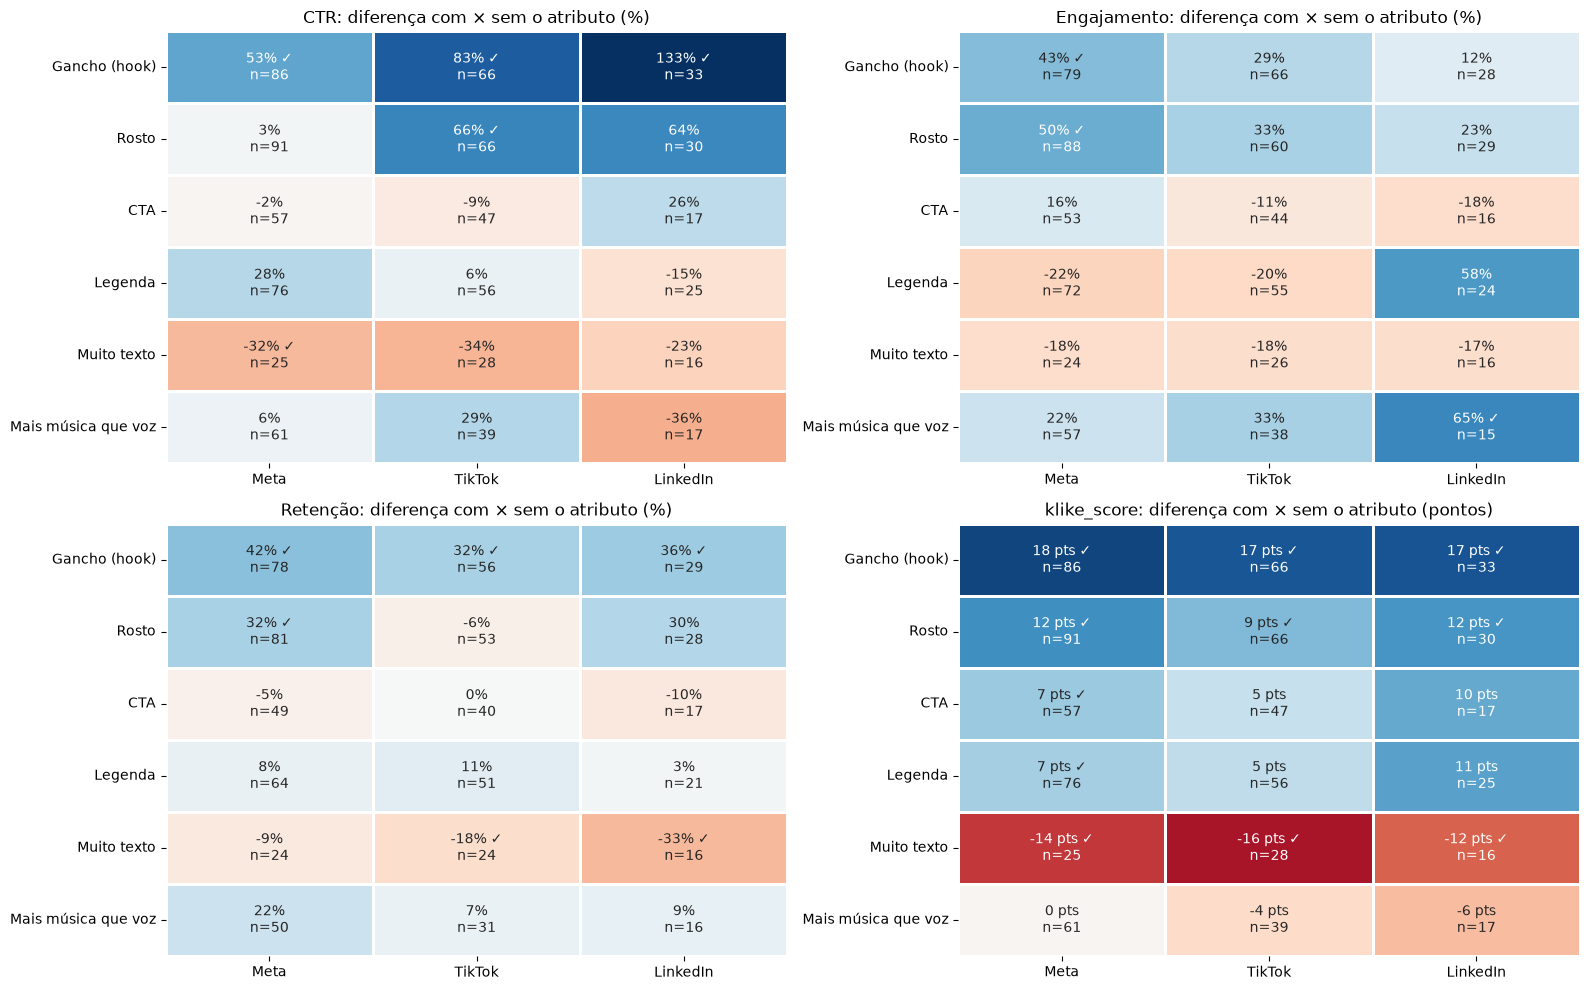

In [8]:
fig, eixos = plt.subplots(2, 2, figsize=(16, 10))
for ax, nome in zip(eixos.flat, METRICAS.values()):
    parte = por_plataforma[por_plataforma["métrica"] == nome]
    coluna_valor = "diferença (pontos)" if nome == "klike_score" else "diferença (%)"
    valores = parte.pivot(index="atributo", columns="plataforma", values=coluna_valor).loc[list(ATRIBUTOS), PLATAFORMAS]
    n = parte.pivot(index="atributo", columns="plataforma", values="n menor grupo").loc[list(ATRIBUTOS), PLATAFORMAS]
    confiavel = parte.pivot(index="atributo", columns="plataforma", values="confiável?").loc[list(ATRIBUTOS), PLATAFORMAS]
    unidade = " pts" if nome == "klike_score" else "%"
    rotulos = (valores.round(0).astype(int).astype(str) + unidade + np.where(confiavel, " ✓", "") + "\nn=" + n.astype(str))
    rotulos = rotulos.where(n >= 15, "n=" + n.astype(str))
    limite = 20 if nome == "klike_score" else 100
    sns.heatmap(valores.where(n >= 15), annot=rotulos, fmt="", cmap="RdBu", center=0, vmin=-limite, vmax=limite,
                cbar=False, ax=ax, linewidths=2, linecolor="white")
    ax.set_title(f"{nome}: diferença com × sem o atributo" + (" (pontos)" if nome == "klike_score" else " (%)"))
    ax.set_xlabel("")
    ax.set_ylabel("")
plt.tight_layout()
plt.show()

**Pelos heatmaps (efeito de cada atributo em cada rede):**

- **Gancho:** sobe a nota em cerca de 17 pontos nas três redes (Meta +18,3, TikTok +17,0, LinkedIn +17,3), sobe a retenção nas três (+32% a +42%) e o CTR nas três (+53% no Meta, +83% no TikTok, +133% no LinkedIn), sempre confiável.
- **Rosto:** sobe a nota nas três (+9 a +12 pontos). No CTR, só é confiável no TikTok (+66%); na retenção, ajuda no Meta (+32%) e no LinkedIn (+30%), mas não no TikTok (−6%).
- **Muito texto:** derruba a nota nas três (−12 a −16 pontos) e a retenção nas três (−9% a −33%). No CTR, a queda tem o mesmo sinal nas três, mas só é confiável no Meta (−32%).
- **CTA e legenda:** sobem a nota nas três (+5 a +11 pontos), mas só são confiáveis no Meta, a rede com mais criativos.
- **"Mais música que voz":** não muda a nota de forma confiável em nenhuma rede, nesta comparação simples.

A leitura célula a célula sugere diferenças (o gancho parece valer muito mais no CTR do LinkedIn). O passo 3 testa se essas diferenças são reais.

## Passo 3: o efeito de um atributo muda de uma rede para outra?

O passo 2 dá o efeito de cada atributo em cada rede. Para saber se o efeito **muda** entre duas redes, não basta olhar se cada um é confiável: preciso da **diferença entre os efeitos** e de um intervalo para ela.

A conta, para cada atributo, métrica e par de redes:
- efeito na rede A − efeito na rede B (em pontos para a nota; em pontos percentuais para as outras métricas);
- o intervalo de 95% vem dos mesmos 2000 sorteios do bootstrap do passo 2: em cada sorteio, subtraio o efeito da rede B do efeito da rede A;
- **diferença confiável** = o intervalo inteiro de um lado do zero: o atributo pesa mais numa rede do que na outra.

Pares com menos de 15 criativos num dos grupos ficam de fora.

In [9]:
PARES = [("Meta", "TikTok"), ("Meta", "LinkedIn"), ("TikTok", "LinkedIn")]
n_menor = por_plataforma.set_index(["plataforma", "atributo", "métrica"])["n menor grupo"]
efeito = por_plataforma.assign(efeito=np.where(por_plataforma["métrica"] == "klike_score", por_plataforma["diferença (pontos)"],
                                               por_plataforma["diferença (%)"])).set_index(["plataforma", "atributo", "métrica"])["efeito"]
linhas = []
for atributo in ATRIBUTOS:
    for nome in METRICAS.values():
        for a, b in PARES:
            if min(n_menor[a, atributo, nome], n_menor[b, atributo, nome]) < 15:
                continue
            baixo, alto = np.percentile(sorteios[a, atributo, nome] - sorteios[b, atributo, nome], [2.5, 97.5])
            linhas.append({"atributo": atributo, "métrica": nome, "par": f"{a} × {b}", "efeito em A": efeito[a, atributo, nome],
                           "efeito em B": efeito[b, atributo, nome], "A − B": efeito[a, atributo, nome] - efeito[b, atributo, nome],
                           "intervalo baixo": baixo, "intervalo alto": alto, "diferença confiável?": baixo > 0 or alto < 0})
pares = pd.DataFrame(linhas)
print(f"{len(pares)} comparações; {pares['diferença confiável?'].sum()} com diferença confiável entre as redes")

72 comparações; 1 com diferença confiável entre as redes


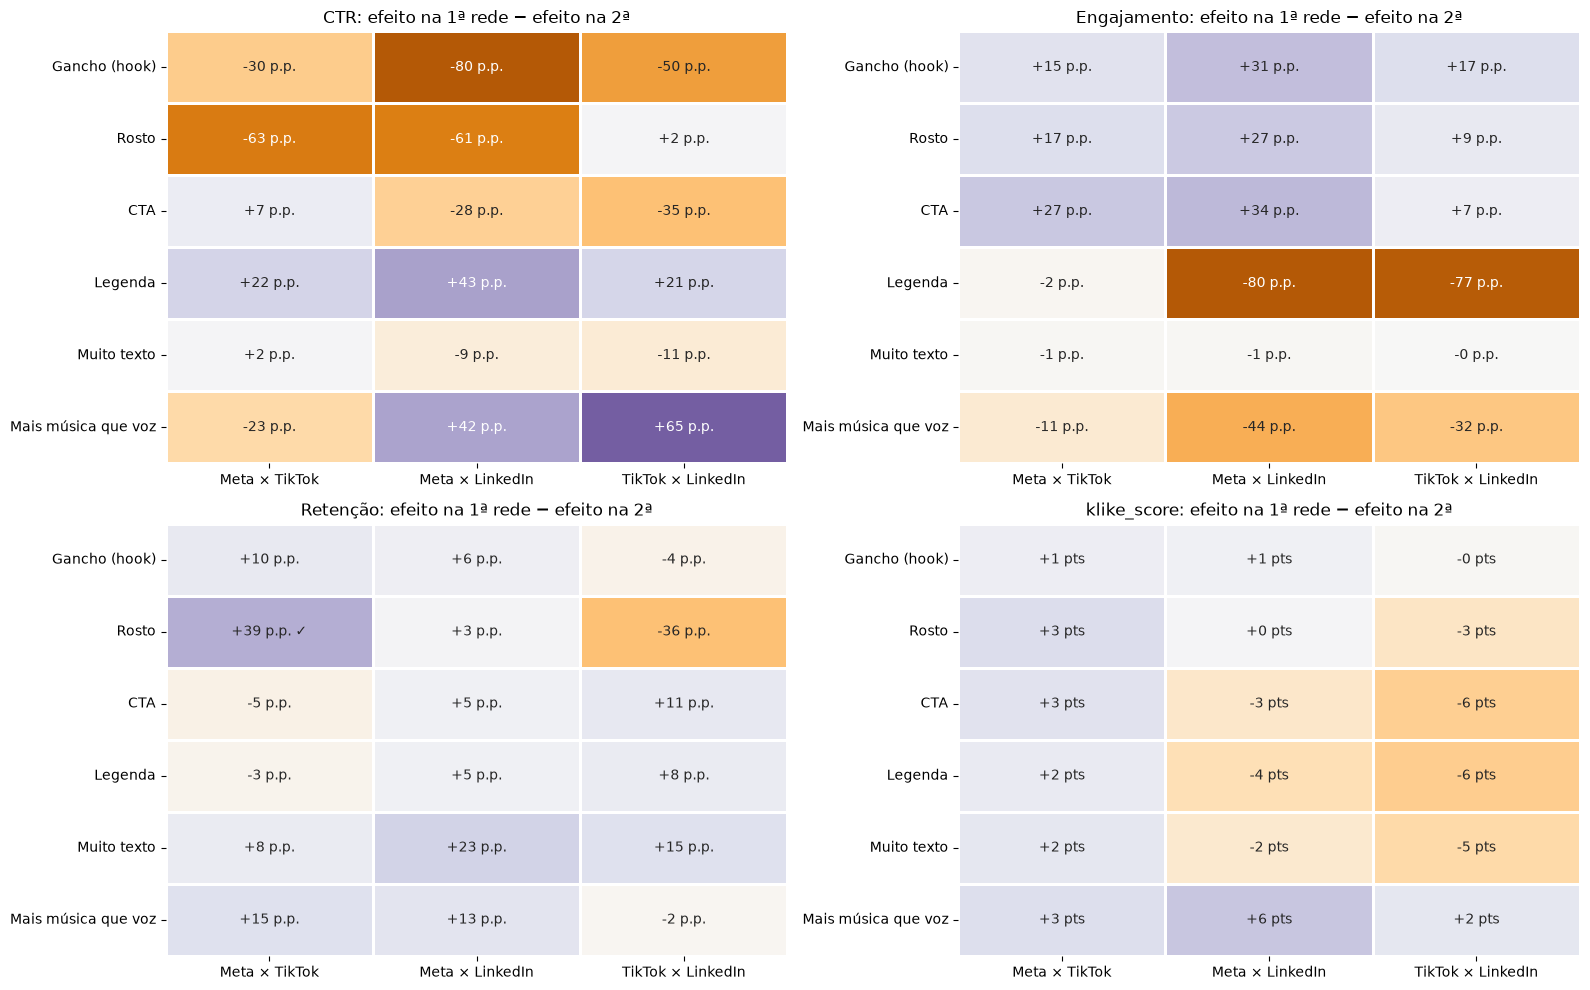

In [10]:
NOMES_PARES = [f"{a} × {b}" for a, b in PARES]
fig, eixos = plt.subplots(2, 2, figsize=(16, 10))
for ax, nome in zip(eixos.flat, METRICAS.values()):
    parte = pares[pares["métrica"] == nome]
    valores = parte.pivot(index="atributo", columns="par", values="A − B").reindex(index=list(ATRIBUTOS), columns=NOMES_PARES)
    confiavel = parte.pivot(index="atributo", columns="par", values="diferença confiável?").reindex(index=list(ATRIBUTOS), columns=NOMES_PARES)
    unidade = " pts" if nome == "klike_score" else " p.p."
    rotulos = valores.map(lambda v: "" if pd.isna(v) else f"{v:+.0f}{unidade}") + np.where(confiavel == True, " ✓", "")
    rotulos = rotulos.where(valores.notna(), "n<15")
    limite = 20 if nome == "klike_score" else 100
    sns.heatmap(valores, annot=rotulos, fmt="", cmap="PuOr", center=0, vmin=-limite, vmax=limite,
                cbar=False, ax=ax, linewidths=2, linecolor="white")
    ax.set_title(f"{nome}: efeito na 1ª rede − efeito na 2ª")
    ax.set_xlabel("")
    ax.set_ylabel("")
plt.tight_layout()
plt.show()

In [11]:
# Só as comparações em que o efeito muda de forma confiável entre as redes
pares[pares["diferença confiável?"]].round(1)

,atributo,métrica,par,efeito em A,efeito em B,A − B,intervalo baixo,intervalo alto,diferença confiável?
18,Rosto,Retenção,Meta × TikTok,32.4,-6.2,38.6,9.8,63.0,True


**O efeito muda de uma rede para outra?**

- **Quase nunca, de forma confiável:** das 72 comparações (6 atributos × 4 métricas × 3 pares), **só 1 tem diferença confiável**: o rosto na retenção, Meta × TikTok (+32% no Meta, −6% no TikTok; diferença de 39 pontos percentuais, intervalo de 10 a 63).
- **Isso é menos do que o acaso produziria:** com intervalos de 95%, umas 3 ou 4 em 72 dariam "diferença" só por sorte. Então, nas medianas simples, **não há sinal de que o que funciona mude de rede para rede.**
- **Cuidado: não achar diferença não prova que os efeitos são iguais.** Os intervalos das diferenças são largos (largura mediana de cerca de 90 pontos percentuais no par Meta × TikTok e de cerca de 130 nos pares com o LinkedIn). Por isso, o "+53% contra +133%" do gancho no CTR não é uma diferença confiável. Com estes tamanhos, só diferenças grandes seriam detectadas.
- **O par mais bem medido é Meta × TikTok** (as duas redes com mais criativos). Os pares com o LinkedIn quase não conseguem detectar diferenças.

## Passo 4: então, o que funciona igual e o que funciona diferente?

Junto os passos 2 e 3 numa **regra de bolso**, sem teste novo, para cada atributo e métrica:
- **funciona igual nas 3:** mesmo sinal nas três redes, confiável em pelo menos duas, e nenhum par com diferença confiável;
- **mesma direção, força diferente:** mesmo sinal nas três, mas algum par com diferença confiável (o atributo ajuda em todas, mais numa do que noutra);
- **funciona diferente:** confiável numa rede e com o sinal oposto em outra;
- **não dá para afirmar:** o resto (efeito pequeno ou poucos criativos).

In [12]:
def classificar(atributo, nome):
    parte = por_plataforma[(por_plataforma["atributo"] == atributo) & (por_plataforma["métrica"] == nome)
                           & (por_plataforma["n menor grupo"] >= 15)]
    sinais = np.sign(parte["diferença (%)"])
    muda = pares.loc[(pares["atributo"] == atributo) & (pares["métrica"] == nome), "diferença confiável?"].any()
    if parte["confiável?"].any() and (sinais > 0).any() and (sinais < 0).any():
        return "funciona diferente"
    if len(parte) == 3 and (sinais == sinais.iloc[0]).all() and parte["confiável?"].sum() >= 2:
        return "mesma direção, força diferente" if muda else "funciona igual nas 3"
    return "não dá para afirmar"


veredito = pd.DataFrame({nome: {atributo: classificar(atributo, nome) for atributo in ATRIBUTOS} for nome in METRICAS.values()})
veredito

,CTR,Engajamento,Retenção,klike_score
Gancho (hook),funciona igual nas 3,não dá para afirmar,funciona igual nas 3,funciona igual nas 3
Rosto,não dá para afirmar,não dá para afirmar,funciona diferente,funciona igual nas 3
CTA,não dá para afirmar,não dá para afirmar,não dá para afirmar,não dá para afirmar
Legenda,não dá para afirmar,não dá para afirmar,não dá para afirmar,não dá para afirmar
Muito texto,não dá para afirmar,não dá para afirmar,funciona igual nas 3,funciona igual nas 3
Mais música que voz,não dá para afirmar,não dá para afirmar,não dá para afirmar,não dá para afirmar


A comparação simples tem um limite: ela mistura o atributo com tudo o que vem junto dele. Para olhar a nota "mantendo o resto igual" **dentro de cada rede**, repito a regressão linear do notebook 1.2 separadamente para cada plataforma (com menos colunas de contexto, porque o LinkedIn tem poucos criativos), com o intervalo de 95% por bootstrap. Aqui a música/voz entra como número de 0 (só voz) a 1 (só música).

Depois comparo os pesos **par a par**, do mesmo jeito do passo 3: em cada um dos 1000 sorteios, peso na rede A − peso na rede B.

In [13]:
REFERENCIAS = {"has_subtitle": ["nao", "sim", "desconhecido"], "text_density": ["medium", "low", "high"]}
colunas = ["has_hook", "has_face", "has_cta", "has_subtitle", "text_density", "music_voice_ratio", "video_duration_s",
           "is_retargeting", "category", "target_audience_age"]
NOMES = {"has_hook": "Gancho (hook)", "has_face": "Rosto", "has_cta": "CTA", "has_subtitle_sim": "Legenda (× não ter)",
         "text_density_low": "Pouco texto (× médio)", "text_density_high": "Muito texto (× médio)",
         "music_voice_ratio": "Só música (× só voz)"}

pesos_por_plataforma, pesos, pesos_sorteados = {}, {}, {}
for plataforma in PLATAFORMAS:
    parte = reais[reais["platform"] == plataforma].dropna(subset=["music_voice_ratio", "video_duration_s"]).copy()
    for coluna, ordem in REFERENCIAS.items():
        parte[coluna] = pd.Categorical(parte[coluna], categories=ordem)
    X = pd.get_dummies(parte[colunas], drop_first=True, dtype=float)
    X[["has_hook", "has_face", "has_cta", "is_retargeting"]] = X[["has_hook", "has_face", "has_cta", "is_retargeting"]].astype(float)
    y = parte["klike_score"]
    peso = pd.Series(LinearRegression().fit(X, y).coef_, index=X.columns)
    gerador = np.random.default_rng(42)
    sorteados = pd.DataFrame([LinearRegression().fit(X.iloc[s], y.iloc[s]).coef_
                              for s in (gerador.integers(0, len(X), len(X)) for _ in range(1000))], columns=X.columns)
    pesos[plataforma], pesos_sorteados[plataforma] = peso[list(NOMES)], sorteados[list(NOMES)]
    baixo, alto = sorteados.quantile(0.025), sorteados.quantile(0.975)
    tabela = pd.DataFrame({"peso": peso, "baixo": baixo, "alto": alto}).loc[list(NOMES)]
    pesos_por_plataforma[plataforma] = (tabela["peso"].round(1).astype(str) + " [" + tabela["baixo"].round(1).astype(str)
                                        + " a " + tabela["alto"].round(1).astype(str) + "]")
    print(f"{plataforma}: {len(X)} criativos, {X.shape[1]} colunas")

pd.DataFrame(pesos_por_plataforma).rename(index=NOMES)

Meta: 170 criativos, 17 colunas


TikTok: 120 criativos, 17 colunas


LinkedIn: 53 criativos, 17 colunas


,Meta,TikTok,LinkedIn
Gancho (hook),17.1 [14.5 a 19.4],16.8 [13.7 a 20.4],24.7 [17.9 a 33.2]
Rosto,11.1 [8.3 a 13.8],12.9 [9.8 a 16.2],9.7 [1.1 a 15.5]
CTA,6.8 [4.3 a 9.7],8.0 [5.0 a 11.2],7.6 [-2.5 a 15.6]
Legenda (× não ter),9.1 [5.8 a 12.1],8.9 [5.6 a 12.3],3.1 [-4.6 a 10.6]
Pouco texto (× médio),-8.8 [-11.4 a -6.1],-6.0 [-9.5 a -2.4],-12.6 [-20.2 a -5.2]
Muito texto (× médio),-16.0 [-20.3 a -11.6],-13.1 [-17.8 a -8.2],-20.0 [-29.8 a -11.3]
Só música (× só voz),-1.2 [-7.3 a 5.1],-13.4 [-22.8 a -3.0],-1.8 [-14.9 a 17.8]


In [14]:
# Peso na rede A − peso na rede B, com intervalo de 95%; ✓ = diferença confiável
diferencas_regressao = {}
for a, b in PARES:
    diferenca = pesos_sorteados[a] - pesos_sorteados[b]
    baixo, alto = diferenca.quantile(0.025), diferenca.quantile(0.975)
    pontual = pesos[a] - pesos[b]
    diferencas_regressao[f"{a} × {b}"] = (pontual.round(1).astype(str) + " [" + baixo.round(1).astype(str) + " a "
                                          + alto.round(1).astype(str) + "]" + np.where((baixo > 0) | (alto < 0), " ✓", ""))
pd.DataFrame(diferencas_regressao).rename(index=NOMES)

,Meta × TikTok,Meta × LinkedIn,TikTok × LinkedIn
Gancho (hook),0.3 [-4.2 a 4.1],-7.6 [-16.4 a -0.5] ✓,-7.9 [-16.8 a 0.2]
Rosto,-1.8 [-6.4 a 2.2],1.4 [-5.4 a 10.4],3.2 [-3.6 a 12.9]
CTA,-1.2 [-5.1 a 2.9],-0.8 [-9.0 a 9.6],0.4 [-8.2 a 11.1]
Legenda (× não ter),0.2 [-4.4 a 4.6],6.0 [-2.0 a 14.5],5.8 [-2.2 a 14.1]
Pouco texto (× médio),-2.8 [-7.4 a 1.7],3.8 [-4.1 a 12.0],6.6 [-1.6 a 15.2]
Muito texto (× médio),-2.9 [-9.4 a 3.4],4.0 [-6.0 a 15.0],6.9 [-2.4 a 17.9]
Só música (× só voz),12.2 [0.4 a 23.9] ✓,0.6 [-19.8 a 15.5],-11.6 [-32.2 a 5.3]


Cada célula da primeira tabela: o peso na nota (pontos, mantendo o resto igual dentro da rede) e o intervalo de 95%. Na segunda: peso na 1ª rede − peso na 2ª, com o intervalo; ✓ = diferença confiável.

**O que funciona igual e o que funciona diferente:**

- **Pela regra de bolso:** o gancho **funciona igual nas três** no CTR, na retenção e na nota; o rosto e o muito texto, na nota (o muito texto também na retenção). O único "funciona diferente" é o rosto na retenção (Meta × TikTok, passo 3). O resto fica como "não dá para afirmar", quase sempre por falta de criativos.
- **A regressão dentro de cada rede confirma:** gancho (+17 a +25 pontos), rosto (+10 a +13), muito texto (−13 a −20) e pouco texto (−6 a −13) aparecem nas três redes, com intervalos que não cruzam o zero. CTA e legenda são confiáveis no Meta e no TikTok, mas não no LinkedIn.
- **Comparando os pesos par a par, 2 de 21 diferenças são confiáveis:**
  - **Voz (Meta × TikTok):** um vídeo só com música, sem voz, perde 13,4 pontos no TikTok e 1,2 no Meta. A diferença é de 12,2 pontos (intervalo de 0,4 a 23,9). Contra o LinkedIn (−1,8), a diferença tem o mesmo tamanho (11,6), mas o intervalo cruza o zero, porque o LinkedIn tem poucos criativos. Na comparação simples (passo 2) isso não aparecia: ela misturava a música com os outros atributos.
  - **Gancho (Meta × LinkedIn):** o gancho pesa +24,7 pontos no LinkedIn e +17,1 no Meta; a diferença (7,6 pontos, intervalo de 0,5 a 16,4) está no limite do confiável. Contra o TikTok (+16,8), a diferença é parecida, mas cruza o zero.
- **Com 21 comparações, cerca de 1 sairia confiável por acaso.** Trato as duas como **indícios**: a da voz é a mais forte (o único efeito da música que aparece confiável em alguma rede); a do gancho, a mais frágil.

## Passo 5: existe uma duração ideal por rede?

No notebook 1.2 não apareceu uma duração ideal com todas as redes juntas. Pode ser que cada rede tenha a sua, e as curvas se cancelem quando juntamos tudo.

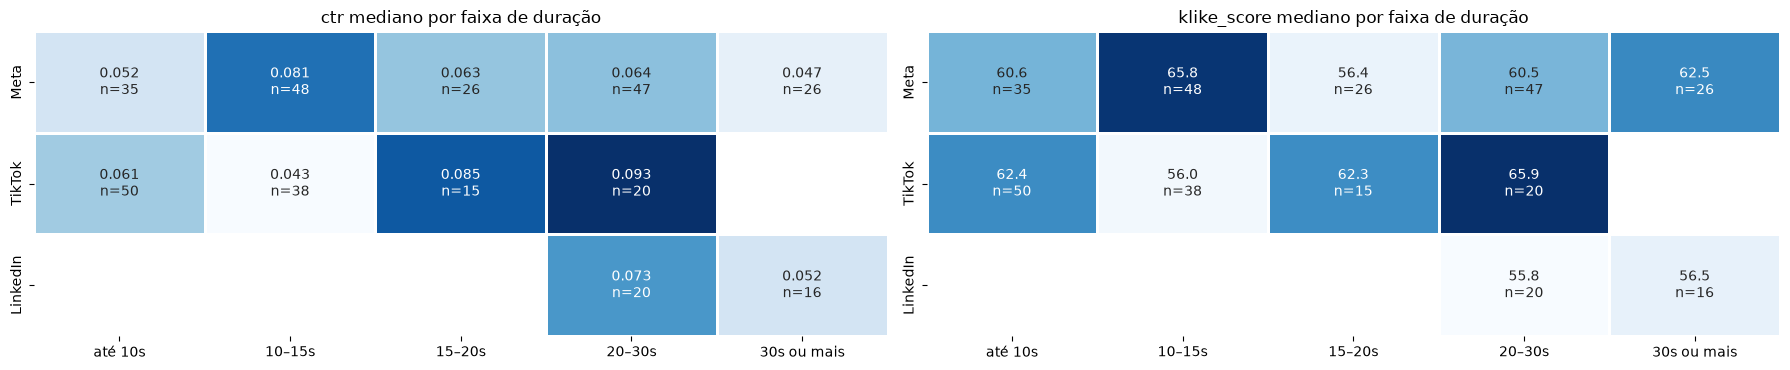

,Meta,TikTok,LinkedIn
eta² da faixa de duração,,,
ctr,0.036,0.081,0.048
klike_score,0.019,0.060,0.096


In [15]:
duracao_real = reais["video_duration_s"].notna()
por_faixa = reais[duracao_real].groupby(["platform", "faixa_duracao"], observed=False).agg(
    criativos=("ctr", "size"), ctr=("ctr", "median"), klike_score=("klike_score", "median"))

fig, eixos = plt.subplots(1, 2, figsize=(18, 3.8))
for ax, metrica, formato in zip(eixos, ["ctr", "klike_score"], [".3f", ".1f"]):
    valores = por_faixa[metrica].unstack().loc[PLATAFORMAS]
    n = por_faixa["criativos"].unstack().loc[PLATAFORMAS]
    rotulos = valores.map(lambda v: f"{v:{formato}}") + "\nn=" + n.astype(str)
    rotulos = rotulos.where(n >= 15, "n=" + n.astype(str))
    sns.heatmap(valores.where(n >= 15), annot=rotulos, fmt="", cmap="Blues", cbar=False, ax=ax, linewidths=2, linecolor="white")
    ax.set_title(f"{metrica} mediano por faixa de duração")
    ax.set_xlabel("")
    ax.set_ylabel("")
plt.tight_layout()
plt.show()

pd.DataFrame({p: {m: eta2(reais.loc[duracao_real & (reais["platform"] == p), m],
                          reais.loc[duracao_real & (reais["platform"] == p), "faixa_duracao"]) for m in ["ctr", "klike_score"]}
              for p in PLATAFORMAS}).round(3).rename_axis("eta² da faixa de duração")

**Duração ideal por rede?** Não de forma consistente. Algumas faixas parecem melhores (por exemplo, 20 a 30 s no TikTok, com CTR de 0,093 contra 0,043 na faixa de 10 a 15 s), mas cada faixa tem poucos criativos (15 a 50), a "melhor faixa" muda de uma métrica para outra, e várias células do LinkedIn têm menos de 15 vídeos. Com 5 faixas e cerca de 130 criativos, só o acaso já dá um eta² perto de 0,03; os valores ficam entre 0,02 e 0,10, sem um padrão claro. **A duração não é o que decide o resultado**; o que acontece nos primeiros segundos (o gancho) pesa muito mais.

## Passo 6: formato × plataforma

Cada rede tem um formato que funciona melhor? Comparo **cada par de formatos dentro de cada rede** (vertical × quadrado, vertical × horizontal, quadrado × horizontal), sempre que os dois grupos têm pelo menos 15 criativos. Atenção às células: o TikTok não tem vídeo horizontal, e o LinkedIn tem pouquíssimos verticais.

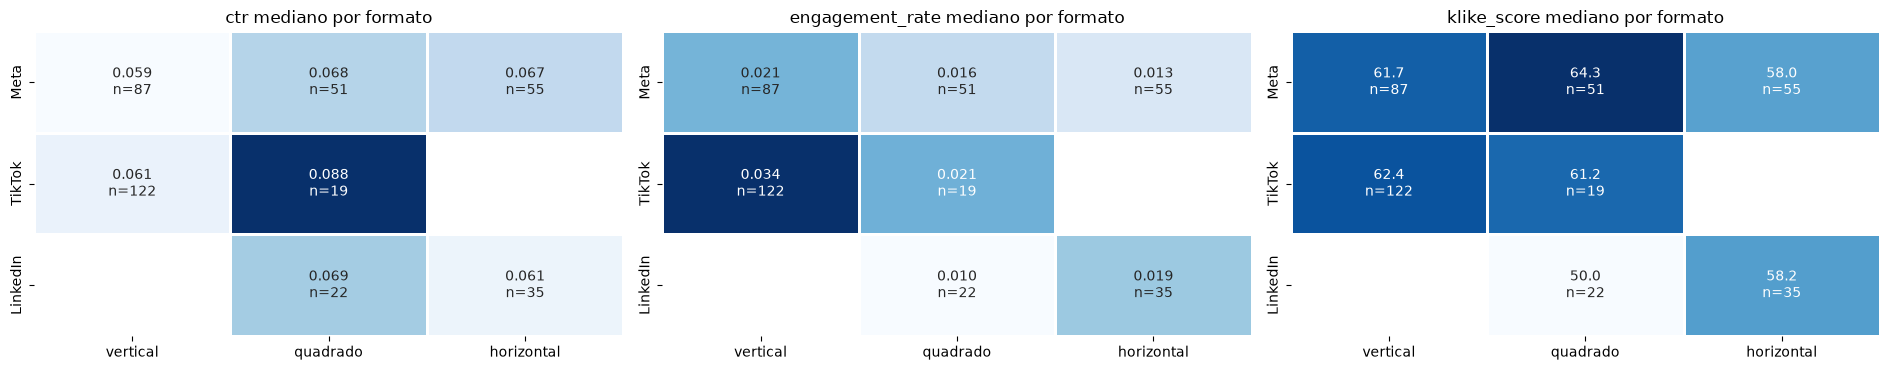

In [16]:
fig, eixos = plt.subplots(1, 3, figsize=(19, 3.8))
for ax, metrica, formato in zip(eixos, ["ctr", "engagement_rate", "klike_score"], [".3f", ".3f", ".1f"]):
    valores = reais.pivot_table(index="platform", columns="format", values=metrica, aggfunc="median").reindex(
        index=PLATAFORMAS, columns=["vertical", "quadrado", "horizontal"])
    n = pd.crosstab(reais["platform"], reais["format"]).reindex(index=PLATAFORMAS, columns=["vertical", "quadrado", "horizontal"]).fillna(0).astype(int)
    rotulos = valores.map(lambda v: f"{v:{formato}}") + "\nn=" + n.astype(str)
    rotulos = rotulos.where(n >= 15, "n=" + n.astype(str))
    sns.heatmap(valores.where(n >= 15), annot=rotulos, fmt="", cmap="Blues", cbar=False, ax=ax, linewidths=2, linecolor="white")
    ax.set_title(f"{metrica} mediano por formato")
    ax.set_xlabel("")
    ax.set_ylabel("")
plt.tight_layout()
plt.show()

In [17]:
# Dentro de cada rede: cada par de formatos com pelo menos 15 criativos de cada lado
PARES_FORMATO = [("vertical", "quadrado"), ("vertical", "horizontal"), ("quadrado", "horizontal")]
linhas = []
for plataforma in PLATAFORMAS:
    parte = reais[reais["platform"] == plataforma]
    for f1, f2 in PARES_FORMATO:
        for metrica in ["ctr", "engagement_rate", "klike_score"]:
            grupo1, grupo2 = parte.loc[parte["format"] == f1, metrica], parte.loc[parte["format"] == f2, metrica]
            if min(grupo1.notna().sum(), grupo2.notna().sum()) >= 15:
                linhas.append({"plataforma": plataforma, "comparação": f"{f1} × {f2}", "métrica": metrica, **comparar(grupo1, grupo2)})
pd.DataFrame(linhas).rename(columns={"n com": "n 1º formato", "n sem": "n 2º formato", "mediana com": "mediana 1º",
                                     "mediana sem": "mediana 2º"}).round(3)

,plataforma,comparação,métrica,n 1º formato,n 2º formato,mediana 1º,mediana 2º,diferença (%),intervalo baixo (%),intervalo alto (%),confiável?
0,Meta,vertical × quadrado,ctr,87,51,0.059,0.068,-12.684,-38.262,43.552,False
1,Meta,vertical × quadrado,engagement_rate,84,45,0.021,0.016,32.188,-11.538,91.200,False
2,Meta,vertical × quadrado,klike_score,87,51,61.700,64.300,-4.044,-15.094,8.497,False
3,Meta,vertical × horizontal,ctr,87,55,0.059,0.067,-11.244,-39.661,27.513,False
4,Meta,vertical × horizontal,engagement_rate,84,51,0.021,0.014,56.667,17.851,139.255,True
5,Meta,vertical × horizontal,klike_score,87,55,61.700,58.000,6.379,-5.747,17.321,False
6,Meta,quadrado × horizontal,ctr,51,55,0.068,0.067,1.649,-38.384,44.321,False
7,Meta,quadrado × horizontal,engagement_rate,45,51,0.016,0.014,18.519,-18.831,100.903,False
8,Meta,quadrado × horizontal,klike_score,51,55,64.300,58.000,10.862,-2.735,21.250,False
9,TikTok,vertical × quadrado,ctr,122,19,0.061,0.088,-30.274,-56.183,61.896,False


**Formato × plataforma:**

- **Nem toda comparação é possível:** o Meta tem os três formatos; o TikTok só permite vertical × quadrado (não tem horizontal); o LinkedIn só permite quadrado × horizontal (só 9 verticais).
- **Das 15 comparações, só 1 é confiável:** no Meta, o vertical engaja 57% mais que o horizontal (0,021 contra 0,014). Na nota e no CTR, nenhum formato ganha de outro de forma confiável, em nenhuma rede.
- **No TikTok, vertical não ganha do quadrado** (nota 62,4 contra 61,2; só 19 quadrados). **No LinkedIn, quadrado e horizontal empatam** dentro da incerteza.
- **Conclusão prática:** dentro de cada rede, o formato pesa pouco. A recomendação é seguir o formato que cada rede já usa.

## Passo 7: texto × plataforma

O próprio enunciado dá o exemplo: "vídeos com muito texto têm desempenho pior no Meta". Os números estão no passo 2 (linha "Muito texto"); aqui, a mediana de cada nível de texto em cada rede.

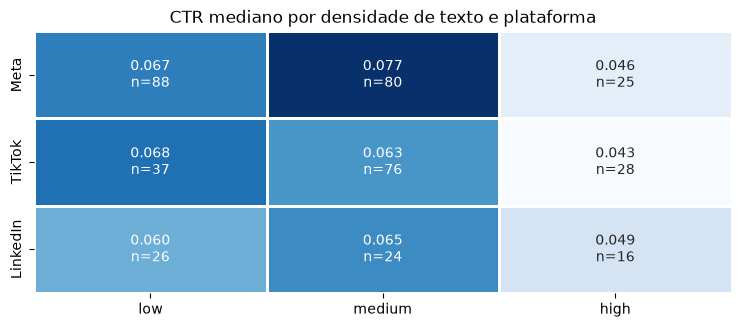

,plataforma,métrica,n com,diferença (%),diferença (pontos),intervalo baixo (%),intervalo alto (%),confiável?
16,Meta,CTR,25,-32.20,-0.02,-67.65,-4.42,True
17,Meta,Engajamento,24,-18.43,-0.00,-64.13,17.42,False
18,Meta,Retenção,24,-9.46,-0.05,-41.40,11.60,False
19,Meta,klike_score,25,-22.36,-14.20,-31.44,-8.31,True
40,TikTok,CTR,28,-34.03,-0.02,-59.89,36.32,False
41,TikTok,Engajamento,26,-17.58,-0.01,-59.55,25.60,False
42,TikTok,Retenção,24,-17.57,-0.09,-32.71,-4.34,True
43,TikTok,klike_score,28,-25.11,-16.45,-39.94,-10.19,True
64,LinkedIn,CTR,16,-23.43,-0.01,-65.40,74.08,False
65,LinkedIn,Engajamento,16,-17.44,-0.00,-58.72,55.52,False


In [18]:
valores = reais.pivot_table(index="platform", columns="text_density", values="ctr", aggfunc="median").loc[PLATAFORMAS, ["low", "medium", "high"]]
n = pd.crosstab(reais["platform"], reais["text_density"]).loc[PLATAFORMAS, ["low", "medium", "high"]]
fig, ax = plt.subplots(figsize=(9, 3.4))
sns.heatmap(valores, annot=valores.map(lambda v: f"{v:.3f}") + "\nn=" + n.astype(str), fmt="", cmap="Blues",
            cbar=False, ax=ax, linewidths=2, linecolor="white")
ax.set_title("CTR mediano por densidade de texto e plataforma")
ax.set_xlabel("")
ax.set_ylabel("")
plt.show()
por_plataforma[por_plataforma["atributo"] == "Muito texto"][["plataforma", "métrica", "n com", "diferença (%)",
                                                           "diferença (pontos)", "intervalo baixo (%)", "intervalo alto (%)", "confiável?"]].round(2)

**Texto × plataforma:**

- **Muito texto derruba a nota nas três redes** (−14,2 no Meta, −16,5 no TikTok, −11,8 no LinkedIn), sempre confiável, e a retenção também cai nas três (confiável no TikTok, −18%, e no LinkedIn, −33%).
- **No CTR, a queda tem o mesmo sinal nas três** (−23% a −34%), mas só é confiável no Meta (−32%), como o exemplo do enunciado sugeria. No TikTok e no LinkedIn há poucos vídeos com muito texto (28 e 16).
- **Pelo passo 3, nenhuma rede difere das outras de forma confiável:** muito texto é um problema comum às três.

## Passo 8: o manual de cada plataforma

Para cada rede, os 3 atributos que mais sobem a nota e os 2 que mais derrubam, pela diferença das medianas do passo 2. "(incerto)" = o intervalo de 95% cruza o zero. A tabela completa vai para `data/processed/efeitos_por_plataforma.csv`, que a Parte 3 (o motor de recomendações) vai usar.

In [19]:
manual = []
for plataforma in PLATAFORMAS:
    nota = por_plataforma[(por_plataforma["plataforma"] == plataforma) & (por_plataforma["métrica"] == "klike_score")
                          & (por_plataforma["n menor grupo"] >= 15)].sort_values("diferença (pontos)", ascending=False)
    descrever = lambda linha: f"{linha['atributo']} {linha['diferença (pontos)']:+.1f} pts" + ("" if linha["confiável?"] else " (incerto)")
    manual.append({"plataforma": plataforma,
                   "fazer (3 maiores)": " · ".join(descrever(l) for _, l in nota.head(3).iterrows()),
                   "evitar (2 piores)": " · ".join(descrever(l) for _, l in nota.tail(2).iloc[::-1].iterrows())})
pd.DataFrame(manual).set_index("plataforma")

,fazer (3 maiores),evitar (2 piores)
plataforma,,
Meta,Gancho (hook) +18.3 pts · Rosto +12.2 pts · CT...,Muito texto -14.2 pts · Mais música que voz -0...
TikTok,Gancho (hook) +17.0 pts · Rosto +8.8 pts · Leg...,Muito texto -16.5 pts · Mais música que voz -3...
LinkedIn,Gancho (hook) +17.3 pts · Rosto +11.8 pts · Le...,Muito texto -11.8 pts · Mais música que voz -6...


In [20]:
saida = por_plataforma.rename(columns={"mediana com": "mediana_com", "mediana sem": "mediana_sem", "diferença (%)": "diferenca_pct",
                                       "n com": "n_com", "n sem": "n_sem", "intervalo baixo (%)": "intervalo_baixo_pct",
                                       "intervalo alto (%)": "intervalo_alto_pct", "confiável?": "confiavel"})
colunas_saida = ["plataforma", "atributo", "métrica", "mediana_com", "mediana_sem", "diferenca_pct", "n_com", "n_sem",
                 "intervalo_baixo_pct", "intervalo_alto_pct", "confiavel"]
saida[colunas_saida].rename(columns={"métrica": "metrica"}).to_csv(RAIZ / "data/processed/efeitos_por_plataforma.csv", index=False)
print("Salvo: data/processed/efeitos_por_plataforma.csv", saida[colunas_saida].shape)

Salvo: data/processed/efeitos_por_plataforma.csv (72, 11)


**O manual:**

| Plataforma | Fazer | Evitar |
|---|---|---|
| **Meta** | gancho (+18,3 pts), rosto (+12,2), CTA (+7,5) | muito texto (−14,2) |
| **TikTok** | gancho (+17,0), rosto (+8,8), legenda (+5,1) | muito texto (−16,5); vídeo só com música, sem voz (−13,4 na regressão) |
| **LinkedIn** | gancho (+17,3), rosto (+11,8), legenda (+10,9) | muito texto (−11,8) |

O "fazer" e o "evitar" quase se repetem nas três redes, como os passos 3 e 4 mostraram. "Mais música que voz" aparece entre os dois piores em todas as redes pela diferença de medianas, mas só no TikTok o efeito é confiável (na regressão).

## Resposta à pergunta 1.3

**Sim, existem padrões diferentes por plataforma, mas eles estão em como cada rede é, e pouco no que funciona nela.**

- **O que muda de rede para rede (o contexto):**
  - **custo:** CPC de R$0,51 no TikTok, R$0,80 no Meta e R$2,49 no LinkedIn; CPA de R$15,9, R$24,2 e R$70,2 (a taxa de conversão é a mesma nas três, cerca de 3,3%);
  - **engajamento:** o TikTok engaja quase o dobro das outras duas;
  - **retorno:** ROAS mediano (sem Branding) de 2,9 no TikTok, 1,9 no Meta e 0,6 no LinkedIn;
  - **o tipo de vídeo:** o TikTok é vertical e curto, o LinkedIn é horizontal ou quadrado e mais longo.
  O CTR e a nota mediana são parecidos nas três.
- **O que funciona é quase o mesmo nas três (o criativo):** gancho (cerca de +17 pontos), rosto (+9 a +12) e evitar muito texto (−12 a −16) valem em todas. Comparando os efeitos par a par, só 1 de 72 diferenças entre redes é confiável, menos do que o acaso daria.
- **As diferenças que apareceram, par a par** (indícios, não certezas):

  | Par | O que muda |
  |---|---|
  | **Meta × TikTok** | **voz:** tirar a voz custa cerca de 12 pontos a mais no TikTok; **rosto:** segura a retenção no Meta (+32%), não no TikTok (−6%) |
  | **Meta × LinkedIn** | **gancho:** pesa um pouco mais no LinkedIn (+24,7 contra +17,1 pontos, no limite do confiável) |
  | **TikTok × LinkedIn** | nenhuma diferença confiável no efeito dos atributos (o LinkedIn tem poucos criativos) |

  Além disso, só no Meta o vertical engaja mais que o horizontal (+57%).
- **Respondendo ao exemplo do case (TikTok × LinkedIn):** o que funciona no TikTok funciona no LinkedIn na **direção**. Não achei nenhuma diferença confiável nesse par, mas é o par com menos criativos para detectar diferenças finas.
- **Para a Parte 3:** o motor de recomendações pode partir de regras comuns às três redes (gancho, rosto, pouco texto na tela) e somar poucos ajustes por rede (a voz no TikTok). O manual e a tabela `data/processed/efeitos_por_plataforma.csv` são a base.